# Intervalos de Confiança na prática
## Caso Olist: a promessa de prazo de entrega

**Disciplina 4 — Decisão com Dados**

### O problema de negócio

A Olist é um marketplace brasileiro. Quando o cliente compra, o checkout mostra um **prazo estimado de entrega**.

- **Produto** quer encurtar esse prazo. Hipótese: prazo menor na tela converte mais.
- **Experiência do Cliente (CX)** tem medo: pedido atrasado vira avaliação ruim.

Nossa missão: responder com dados, e com a incerteza de cada número medida por **intervalos de confiança**.

### Roteiro

1. Carregar os dados
2. EDA univariada (checklist de 6 passos), com limpeza e criação de variáveis
3. EDA bivariada
4. IC para médias
5. IC para proporções
6. Resumo executivo

### Como usar este notebook

Cada célula de código vem depois de um **prompt**. A ideia é colar o prompt na IA, ler o código gerado, avaliar se está certo e só então avaliar o resultado.

Antes de tudo, cole o prompt de contexto abaixo. Ele vale para a conversa inteira.

---
# 1. Carregando os dados

**Prompt**

```text
Carregue 4 arquivos CSV da Olist a partir deste endereço:
https://raw.githubusercontent.com/olist/work-at-olist-data/master/datasets/

Arquivos e nomes das variáveis:
- olist_orders_dataset.csv        -> pedidos
- olist_customers_dataset.csv     -> clientes
- olist_order_reviews_dataset.csv -> avaliacoes
- olist_order_items_dataset.csv   -> itens

Passos:
1. Importe pandas, numpy, matplotlib.pyplot e scipy.stats.
2. Leia os 4 arquivos.
3. Mostre o número de linhas e colunas de cada tabela.
4. Mostre as 3 primeiras linhas de cada tabela.
```

In [ ]:
# 1. Importações
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# 2. Leitura dos 4 arquivos
url_base = "https://raw.githubusercontent.com/olist/work-at-olist-data/master/datasets/"

pedidos    = pd.read_csv(url_base + "olist_orders_dataset.csv")
clientes   = pd.read_csv(url_base + "olist_customers_dataset.csv")
avaliacoes = pd.read_csv(url_base + "olist_order_reviews_dataset.csv")
itens      = pd.read_csv(url_base + "olist_order_items_dataset.csv")

tabelas = {
    "pedidos": pedidos,
    "clientes": clientes,
    "avaliacoes": avaliacoes,
    "itens": itens,
}

# 3. Número de linhas e colunas de cada tabela
for nome, tabela in tabelas.items():
    print(f"{nome:<11} {tabela.shape[0]:>7} linhas | {tabela.shape[1]:>2} colunas")

# 4. As 3 primeiras linhas de cada tabela
for nome, tabela in tabelas.items():
    print(f"\n=== {nome} ===")
    display(tabela.head(3))

pedidos       99441 linhas |  8 colunas
clientes      99441 linhas |  5 colunas
avaliacoes    99224 linhas |  7 colunas
itens        112650 linhas |  7 colunas

=== pedidos ===


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00



=== clientes ===


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP



=== avaliacoes ===


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24



=== itens ===


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


---
# 2. EDA univariada

Aplicamos o checklist de 6 passos da aula de EDA, variável a variável:

1. **Tipo** da variável
2. **Valores únicos**
3. **Ausentes**
4. **Distribuição**
5. **Problemas de qualidade**
6. **Uso** na análise

Quando encontramos um problema, tratamos na hora. Quando precisamos de uma variável nova, criamos na hora.

### 2.1 Tipos e ausentes da tabela `pedidos`

**Prompt**

```text
Na tabela pedidos:
1. Mostre o tipo de cada coluna.
2. Monte uma tabela com a quantidade e o percentual de valores ausentes por coluna.
```

In [ ]:
# tipo de cada coluna
print(pedidos.dtypes)

# ausentes: quantidade e percentual
ausentes = pedidos.isnull().sum()
percentual = ausentes / len(pedidos) * 100

tabela_ausentes = pd.DataFrame({"ausentes": ausentes, "percentual": percentual.round(2)})
tabela_ausentes

order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object


,ausentes,percentual
order_id,0,0.00
customer_id,0,0.00
order_status,0,0.00
order_purchase_timestamp,0,0.00
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98
order_estimated_delivery_date,0,0.00


**Prompt**

```text
Converta para data (datetime) estas colunas da tabela pedidos:
order_purchase_timestamp, order_approved_at, order_delivered_carrier_date,
order_delivered_customer_date, order_estimated_delivery_date.
Use um loop. Depois mostre os tipos das colunas de novo para conferir.
```

In [ ]:
colunas_data = [
    "order_purchase_timestamp",       # compra
    "order_approved_at",              # pagamento aprovado
    "order_delivered_carrier_date",   # entregue à transportadora
    "order_delivered_customer_date",  # entregue ao cliente
    "order_estimated_delivery_date",  # data prometida ao cliente
]

# converte uma coluna por vez
for coluna in colunas_data:
    pedidos[coluna] = pd.to_datetime(pedidos[coluna])

print(pedidos.dtypes)

order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [ ]:
pedidos[pedidos["order_delivered_customer_date"].isnull()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaT,NaT,2017-05-09
44,ee64d42b8cf066f35eac1cf57de1aa85,caded193e8e47b8362864762a83db3c5,shipped,2018-06-04 16:44:48,2018-06-05 04:31:18,2018-06-05 14:32:00,NaT,2018-06-28
103,0760a852e4e9d89eb77bf631eaaf1c84,d2a79636084590b7465af8ab374a8cf5,invoiced,2018-08-03 17:44:42,2018-08-07 06:15:14,NaT,NaT,2018-08-21
128,15bed8e2fec7fdbadb186b57c46c92f2,f3f0e613e0bdb9c7cee75504f0f90679,processing,2017-09-03 14:22:03,2017-09-03 14:30:09,NaT,NaT,2017-10-03
154,6942b8da583c2f9957e990d028607019,52006a9383bf149a4fb24226b173106f,shipped,2018-01-10 11:33:07,2018-01-11 02:32:30,2018-01-11 19:39:23,NaT,2018-02-07
...,...,...,...,...,...,...,...,...
99283,3a3cddda5a7c27851bd96c3313412840,0b0d6095c5555fe083844281f6b093bb,canceled,2018-08-31 16:13:44,NaT,NaT,NaT,2018-10-01
99313,e9e64a17afa9653aacf2616d94c005b8,b4cd0522e632e481f8eaf766a2646e86,processing,2018-01-05 23:07:24,2018-01-09 07:18:05,NaT,NaT,2018-02-06
99347,a89abace0dcc01eeb267a9660b5ac126,2f0524a7b1b3845a1a57fcf3910c4333,canceled,2018-09-06 18:45:47,NaT,NaT,NaT,2018-09-27
99348,a69ba794cc7deb415c3e15a0a3877e69,726f0894b5becdf952ea537d5266e543,unavailable,2017-08-23 16:28:04,2017-08-28 15:44:47,NaT,NaT,2017-09-15


## 2.2 `order_status`

**Prompt**

```text
Analise a coluna order_status da tabela pedidos:
1. Mostre quantos pedidos existem em cada status, em quantidade e percentual.
2. Faça um gráfico de barras com a quantidade por status.
```

              pedidos  percentual
order_status                     
delivered       96478       97.02
shipped          1107        1.11
canceled          625        0.63
unavailable       609        0.61
invoiced          314        0.32
processing        301        0.30
created             5        0.01
approved            2        0.00


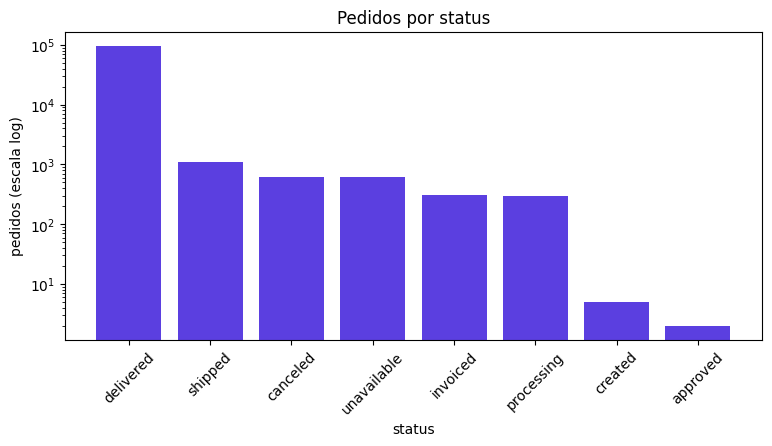

In [ ]:
# contagem e percentual por status
contagem = pedidos["order_status"].value_counts()
percentual = pedidos["order_status"].value_counts(normalize=True) * 100
print(pd.DataFrame({"pedidos": contagem, "percentual": percentual.round(2)}))

# gráfico de barras
plt.figure(figsize=(9, 4))
plt.bar(contagem.index, contagem.values, color="#5B3FE0")
plt.yscale("log")
plt.title("Pedidos por status")
plt.xlabel("status")
plt.ylabel("pedidos (escala log)")
plt.xticks(rotation=45)
plt.show()

**Prompt**

```text
Quero entender os ausentes em order_delivered_customer_date.
1. Crie na tabela pedidos a coluna tem_data_entrega (True se a data de entrega não for nula).
2. Faça uma tabela cruzada (crosstab) entre order_status e tem_data_entrega.
```

In [ ]:
# True quando existe data de entrega ao cliente
pedidos["tem_data_entrega"] = pedidos["order_delivered_customer_date"].notnull()

# cruzando status com a existência da data
pd.crosstab(pedidos["order_status"], pedidos["tem_data_entrega"])

tem_data_entrega,False,True
order_status,,
approved,2,0
canceled,619,6
created,5,0
delivered,8,96470
invoiced,314,0
processing,301,0
shipped,1107,0
unavailable,609,0


**Prompt**

```text
Crie a tabela entregues com os pedidos que:
1. têm order_status igual a "delivered", e
2. têm order_delivered_customer_date preenchida.
Use .copy() no final. Mostre quantos pedidos havia antes e quantos ficaram.
```

In [ ]:
# filtro 1: só pedidos entregues
entregues = pedidos[pedidos["order_status"] == "delivered"]

# filtro 2: só quem tem data de entrega preenchida
entregues = entregues[entregues["order_delivered_customer_date"].notnull()].copy()

print("Pedidos no total:          ", len(pedidos))
print("Entregues com data válida: ", len(entregues))

Pedidos no total:           99441
Entregues com data válida:  96470


## 2.3 `order_purchase_timestamp`: o período dos dados

**Prompt**

```text
Analise a data de compra (order_purchase_timestamp) na tabela pedidos:
1. Mostre a primeira e a última data de compra.
2. Crie a coluna mes com o ano-mês da compra (use .dt.to_period("M")).
3. Conte quantos pedidos existem por mês, em ordem cronológica.
4. Faça um gráfico de barras dessa contagem.
```

Primeira compra: 2016-09-04 21:15:19
Última compra:   2018-10-17 17:30:18
mes
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: count, dtype: int64


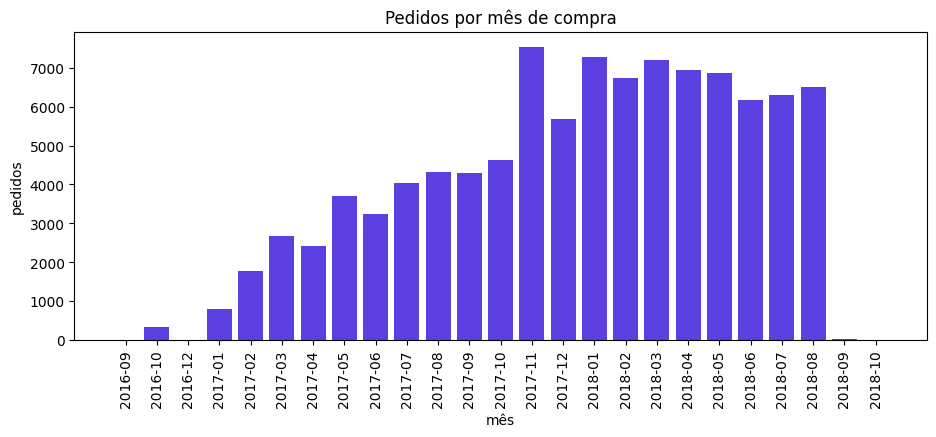

In [ ]:
# período coberto pelos dados
print("Primeira compra:", pedidos["order_purchase_timestamp"].min())
print("Última compra:  ", pedidos["order_purchase_timestamp"].max())

# ano-mês de cada compra
pedidos["mes"] = pedidos["order_purchase_timestamp"].dt.to_period("M")

# pedidos por mês, em ordem cronológica
pedidos_por_mes = pedidos["mes"].value_counts().sort_index()
print(pedidos_por_mes)

# gráfico
plt.figure(figsize=(11, 4))
plt.bar(pedidos_por_mes.index.astype(str), pedidos_por_mes.values, color="#5B3FE0")
plt.title("Pedidos por mês de compra")
plt.xlabel("mês")
plt.ylabel("pedidos")
plt.xticks(rotation=90)
plt.show()

## 2.4 Criando as variáveis de prazo

Ainda não temos as variáveis que respondem a pergunta de negócio. Vamos criá-las. Antes, um cuidado: a data prometida tem horário?

**Prompt**

```text
Na tabela entregues, crie três colunas:
1. dias_entrega: dias entre a compra e a entrega ao cliente (com decimais).
   Use .dt.total_seconds() e divida pelo número de segundos em um dia.
2. dias_prometidos: dias entre a compra e a data prometida (mesma lógica).
3. atrasou: True se o DIA da entrega for depois da data prometida.
   Use .dt.normalize() para zerar o horário da entrega antes de comparar
```

In [ ]:
segundos_por_dia = 24 * 60 * 60

# tempo real de entrega, em dias
tempo_entrega = entregues["order_delivered_customer_date"] - entregues["order_purchase_timestamp"]
entregues["dias_entrega"] = tempo_entrega.dt.total_seconds() / segundos_por_dia

# prazo prometido, em dias
tempo_prometido = entregues["order_estimated_delivery_date"] - entregues["order_purchase_timestamp"]
entregues["dias_prometidos"] = tempo_prometido.dt.total_seconds() / segundos_por_dia

# atraso comparando só o dia (normalize zera o horário)
dia_da_entrega = entregues["order_delivered_customer_date"].dt.normalize()
entregues["atrasou"] = dia_da_entrega > entregues["order_estimated_delivery_date"]


print(f"Taxa de atraso (por dia, correto): {entregues['atrasou'].mean() * 100:.2f}%")


Taxa de atraso (por dia, correto): 6.77%


In [ ]:
entregues

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,tem_data_entrega,dias_entrega,dias_prometidos,atrasou
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,True,8.436574,15.544063,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,True,13.782037,19.137766,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,True,9.394213,26.639711,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,True,13.208750,26.188819,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,True,2.873877,12.112049,False
...,...,...,...,...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,True,8.218009,18.587442,False
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,True,22.193727,23.459051,False
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,True,24.859421,30.384225,False
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,True,17.086424,37.105243,False


**Prompt**

```text
Faça checagens de qualidade das datas na tabela entregues. Conte quantos pedidos têm:
1. dias_entrega negativo.
2. data de entrega à transportadora (order_delivered_carrier_date) antes da compra.
3. data de entrega ao cliente antes da data de entrega à transportadora.
```

In [ ]:
# 1. entrega antes da compra: impossível
entrega_negativa = (entregues["dias_entrega"] < 0).sum()

# 2. despacho antes da compra: impossível
despacho_antes_compra = (entregues["order_delivered_carrier_date"] < entregues["order_purchase_timestamp"]).sum()

# 3. chegou ao cliente antes de sair para a transportadora: impossível
chegou_antes_despacho = (entregues["order_delivered_customer_date"] < entregues["order_delivered_carrier_date"]).sum()

print("Tempo de entrega negativo:        ", entrega_negativa)
print("Despacho antes da compra:         ", despacho_antes_compra)
print("Chegou antes de sair p/ transport.:", chegou_antes_despacho)

Tempo de entrega negativo:         0
Despacho antes da compra:          165
Chegou antes de sair p/ transport.: 23


**Prompt**

Remova da entregues aquelas que tem despacho antes da compra e chegou antes de sair pra transportadora TRUE

In [ ]:
# Flags de inconsistência nas datas
despacho_antes_compra = entregues["order_delivered_carrier_date"] < entregues["order_purchase_timestamp"]
entrega_antes_despacho = entregues["order_delivered_customer_date"] < entregues["order_delivered_carrier_date"]

inconsistente = despacho_antes_compra | entrega_antes_despacho

print(f"Despacho antes da compra:          {despacho_antes_compra.sum()}")
print(f"Entrega antes do despacho:         {entrega_antes_despacho.sum()}")
print(f"Total a remover (qualquer um True): {inconsistente.sum()}")

# Remove os pedidos inconsistentes
antes = len(entregues)
entregues = entregues[~inconsistente].copy()
print(f"\nPedidos antes: {antes} | depois: {len(entregues)} | removidos: {antes - len(entregues)}")


Despacho antes da compra:          165
Entrega antes do despacho:         23
Total a remover (qualquer um True): 188

Pedidos antes: 96470 | depois: 96282 | removidos: 188


## 2.5 `dias_entrega`

**Prompt**

```text
Analise a distribuição de dias_entrega na tabela entregues:
1. Mostre as estatísticas descritivas (describe), arredondadas em 1 casa.
2. Faça, lado a lado, um histograma e um boxplot horizontal.
3. Conte quantos pedidos (e qual %) passam de 30, 60 e 100 dias.
```

count    96282.0
mean        12.6
std          9.6
min          0.5
25%          6.8
50%         10.2
75%         15.7
max        209.6
Name: dias_entrega, dtype: float64


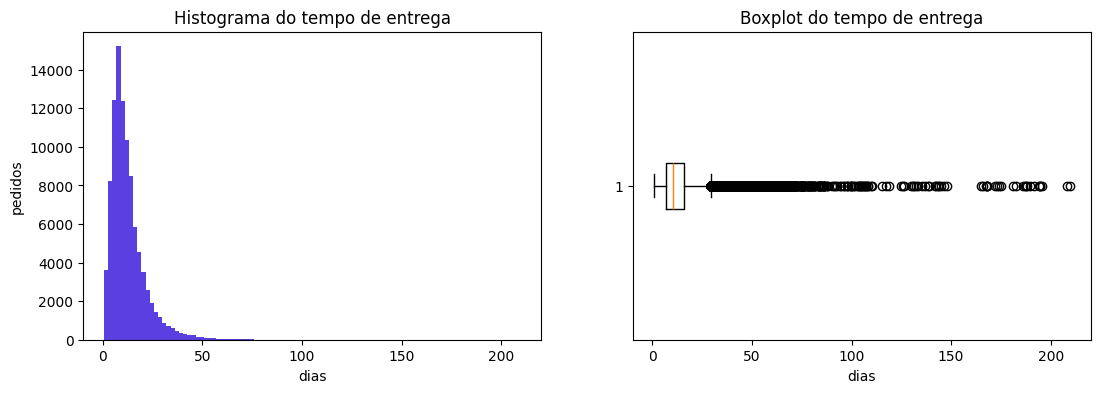

Acima de 30 dias: 4549 pedidos (4.72%)
Acima de 60 dias: 306 pedidos (0.32%)
Acima de 100 dias: 64 pedidos (0.07%)


In [ ]:
# estatísticas descritivas
print(entregues["dias_entrega"].describe().round(1))

# histograma e boxplot lado a lado
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))

eixos[0].hist(entregues["dias_entrega"], bins=100, color="#5B3FE0")
eixos[0].set_title("Histograma do tempo de entrega")
eixos[0].set_xlabel("dias")
eixos[0].set_ylabel("pedidos")

eixos[1].boxplot(entregues["dias_entrega"], vert=False)
eixos[1].set_title("Boxplot do tempo de entrega")
eixos[1].set_xlabel("dias")

plt.show()

# quantos pedidos passam de cada limite
for limite in [30, 60, 100]:
    quantidade = (entregues["dias_entrega"] > limite).sum()
    percentual = quantidade / len(entregues) * 100
    print(f"Acima de {limite} dias: {quantidade} pedidos ({percentual:.2f}%)")

## 2.6 `dias_prometidos`

**Prompt**

```text
Analise dias_prometidos na tabela entregues:
1. Mostre o describe arredondado em 1 casa.
2. Faça um histograma com 60 bins.
3. Imprima a média de dias_prometidos e a média de dias_entrega, lado a lado.
```

count    96282.0
mean        23.7
std          8.8
min          2.0
25%         18.3
50%         23.2
75%         28.4
max        155.1
Name: dias_prometidos, dtype: float64


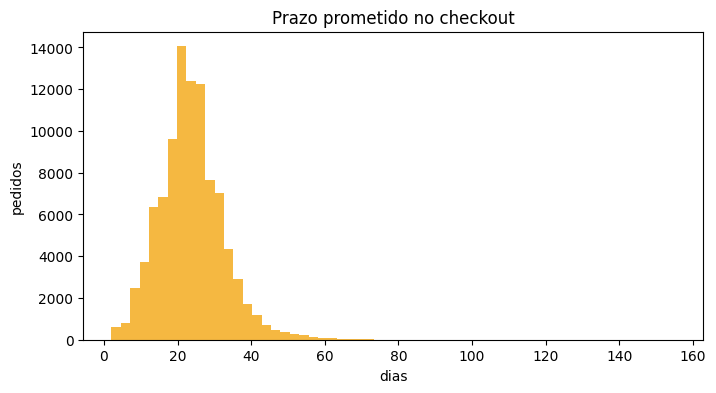

Prazo prometido médio: 23.7 dias
Entrega real média:    12.6 dias


In [ ]:
print(entregues["dias_prometidos"].describe().round(1))

plt.figure(figsize=(8, 4))
plt.hist(entregues["dias_prometidos"], bins=60, color="#F5B841")
plt.title("Prazo prometido no checkout")
plt.xlabel("dias")
plt.ylabel("pedidos")
plt.show()

print(f"Prazo prometido médio: {entregues['dias_prometidos'].mean():.1f} dias")
print(f"Entrega real média:    {entregues['dias_entrega'].mean():.1f} dias")

## 2.7 `atrasou`

**Prompt**

```text
Mostre quantos pedidos atrasaram e quantos não atrasaram na tabela entregues,
em quantidade e em percentual.
```

In [ ]:
print(entregues["atrasou"].value_counts())
print()
print((entregues["atrasou"].value_counts(normalize=True) * 100).round(2))

atrasou
False    89750
True      6532
Name: count, dtype: int64

atrasou
False    93.22
True      6.78
Name: proportion, dtype: float64


## 2.8 `review_score`

**Prompt**

```text
Analise a coluna review_score da tabela avaliacoes:
1. Mostre a contagem e o percentual de cada nota, em ordem de 1 a 5.
2. Faça um gráfico de barras do percentual. Pinte as notas 1 e 2 de #F0665A,
   a nota 3 de cinza e as notas 4 e 5 de #5B3FE0.
3. Conte quantos order_id aparecem mais de uma vez (pedidos com mais de uma avaliação).
```

              avaliacoes  percentual
review_score                        
1                  11424        11.5
2                   3151         3.2
3                   8179         8.2
4                  19142        19.3
5                  57328        57.8


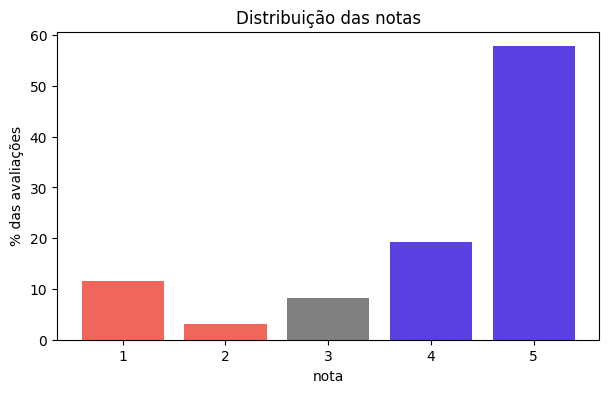

Pedidos com mais de uma avaliação: 551


In [ ]:
# contagem e percentual por nota
contagem_notas = avaliacoes["review_score"].value_counts().sort_index()
percentual_notas = avaliacoes["review_score"].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({"avaliacoes": contagem_notas, "percentual": percentual_notas.round(1)}))

# gráfico com cores por grupo de nota
cores = ["#F0665A", "#F0665A", "gray", "#5B3FE0", "#5B3FE0"]
plt.figure(figsize=(7, 4))
plt.bar(percentual_notas.index, percentual_notas.values, color=cores)
plt.title("Distribuição das notas")
plt.xlabel("nota")
plt.ylabel("% das avaliações")
plt.show()

# pedidos com mais de uma avaliação
duplicados = avaliacoes["order_id"].duplicated().sum()
print("Pedidos com mais de uma avaliação:", duplicados)

**Prompt**

```text
1. Ordene avaliacoes por review_answer_timestamp.
2. Remova order_id duplicados mantendo a última avaliação. Guarde só as colunas
   order_id e review_score em avaliacoes_final.
3. Junte avaliacoes_final na tabela entregues (merge pelo order_id, how="left") em um novo dataframe chamado entregues_aval.
4. Crie a coluna nota_ruim: 1 se review_score for 1 ou 2, 0 caso contrário.
   Pedidos sem avaliação devem ficar com nota_ruim vazia (NaN), não com 0.
5. Mostre o % de pedidos entregues sem avaliação.
```

In [ ]:
# 1. ordenar pela data de resposta
avaliacoes = avaliacoes.sort_values("review_answer_timestamp")

# 2. uma avaliação por pedido (a última)
avaliacoes_final = (
    avaliacoes.drop_duplicates(subset="order_id", keep="last")[["order_id", "review_score"]]
)

# 3. juntar na própria tabela entregues
entregues = entregues.drop(columns=["review_score", "nota_ruim"], errors="ignore")
entregues_aval = entregues.merge(avaliacoes_final, on="order_id", how="left")

# 4. nota_ruim: 1 para notas 1 ou 2, 0 para as outras
entregues_aval["nota_ruim"] = entregues_aval["review_score"].isin([1, 2]).astype(float)

# quem não avaliou fica vazio, para não contar como "nota boa"
sem_avaliacao = entregues_aval["review_score"].isnull()
entregues_aval.loc[sem_avaliacao, "nota_ruim"] = np.nan

# 5. quanto ficou sem avaliação
print(f"Pedidos entregues sem avaliação: {sem_avaliacao.mean() * 100:.2f}%")


Pedidos entregues sem avaliação: 0.67%


## 2.9 `customer_state` (UF do cliente)

**Prompt**

```text
1. Junte a coluna customer_state da tabela clientes na tabela entregues_aval
   (merge pelo customer_id, how="left") e renomeie para uf.
2. Mostre quantos pedidos existem por uf, do maior para o menor.
3. Faça um gráfico de barras
4. Crie um dicionário uf_para_regiao que liga cada UF à sua região
   (Norte, Nordeste, Centro-Oeste, Sudeste, Sul) e crie a coluna regiao.
5. Mostre quantos pedidos existem por região.
```

uf
SP    40428
RJ    12330
MG    11327
RS     5327
PR     4912
SC     3534
BA     3252
DF     2077
ES     1989
GO     1951
PE     1592
CE     1278
PA      945
MT      883
MA      714
MS      699
PB      517
RN      474
PI      473
AL      397
SE      334
TO      273
RO      243
AM      145
AC       80
AP       67
RR       41
Name: count, dtype: int64
uf
SP    40428
RJ    12330
MG    11327
RS     5327
PR     4912
SC     3534
BA     3252
DF     2077
ES     1989
GO     1951
PE     1592
CE     1278
PA      945
MT      883
MA      714
MS      699
PB      517
RN      474
PI      473
AL      397
SE      334
TO      273
RO      243
AM      145
AC       80
AP       67
RR       41
Name: count, dtype: int64


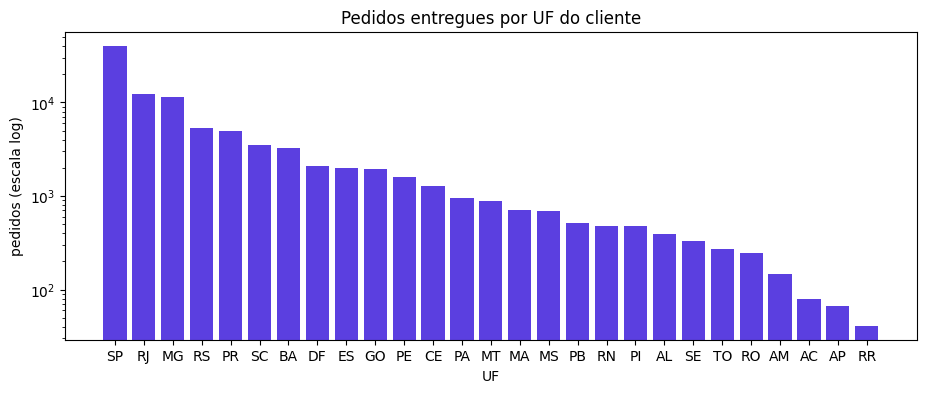

regiao
Sudeste         66074
Sul             13773
Nordeste         9031
Centro-Oeste     5610
Norte            1794
Name: count, dtype: int64


In [ ]:
# 1. traz a UF do cliente
entregues_aval = entregues_aval.merge(clientes[["customer_id", "customer_state"]], on="customer_id", how="left")
entregues_aval = entregues_aval.rename(columns={"customer_state": "uf"})

# 2. pedidos por UF
pedidos_por_uf = entregues_aval["uf"].value_counts()
print(pedidos_por_uf)


# 1. pedidos por UF
pedidos_por_uf = entregues_aval["uf"].value_counts()
print(pedidos_por_uf)

# 3. gráfico
plt.figure(figsize=(11, 4))
plt.bar(pedidos_por_uf.index, pedidos_por_uf.values, color="#5B3FE0")
plt.yscale("log")
plt.title("Pedidos entregues por UF do cliente")
plt.xlabel("UF")
plt.ylabel("pedidos (escala log)")
plt.show()

# 4. cada UF na sua região
uf_para_regiao = {
    "AC": "Norte", "AP": "Norte", "AM": "Norte", "PA": "Norte", "RO": "Norte", "RR": "Norte", "TO": "Norte",
    "AL": "Nordeste", "BA": "Nordeste", "CE": "Nordeste", "MA": "Nordeste", "PB": "Nordeste",
    "PE": "Nordeste", "PI": "Nordeste", "RN": "Nordeste", "SE": "Nordeste",
    "DF": "Centro-Oeste", "GO": "Centro-Oeste", "MT": "Centro-Oeste", "MS": "Centro-Oeste",
    "ES": "Sudeste", "MG": "Sudeste", "RJ": "Sudeste", "SP": "Sudeste",
    "PR": "Sul", "RS": "Sul", "SC": "Sul",
}
entregues_aval["regiao"] = entregues_aval["uf"].map(uf_para_regiao)

# 5. pedidos por região
print(entregues_aval["regiao"].value_counts())

---
# 3. EDA bivariada

Agora cruzamos variáveis. Quatro perguntas:

1. A operação é estável **no tempo**?
2. O prazo muda por **região**?
3. Quanta **folga** a promessa tem, por região?
4. O **atraso** tem relação com a **nota**?

### 3.1 Tempo × operação

**Prompt**

```text
Na tabela entregues_aval
1. Agrupe por mes e calcule: número de pedidos, média de dias_entrega,média de dias_prometidos e taxa de atraso (média de atrasou).
Guarde em por_mes.
2. Faça 3 gráficos de linha, um embaixo do outro, com o mesmo eixo x:
   (a) pedidos por mês; (b) prometido e real no mesmo gráfico; (c) taxa de atraso em %.
3. Mostre as últimas 10 linhas de por_mes.
```

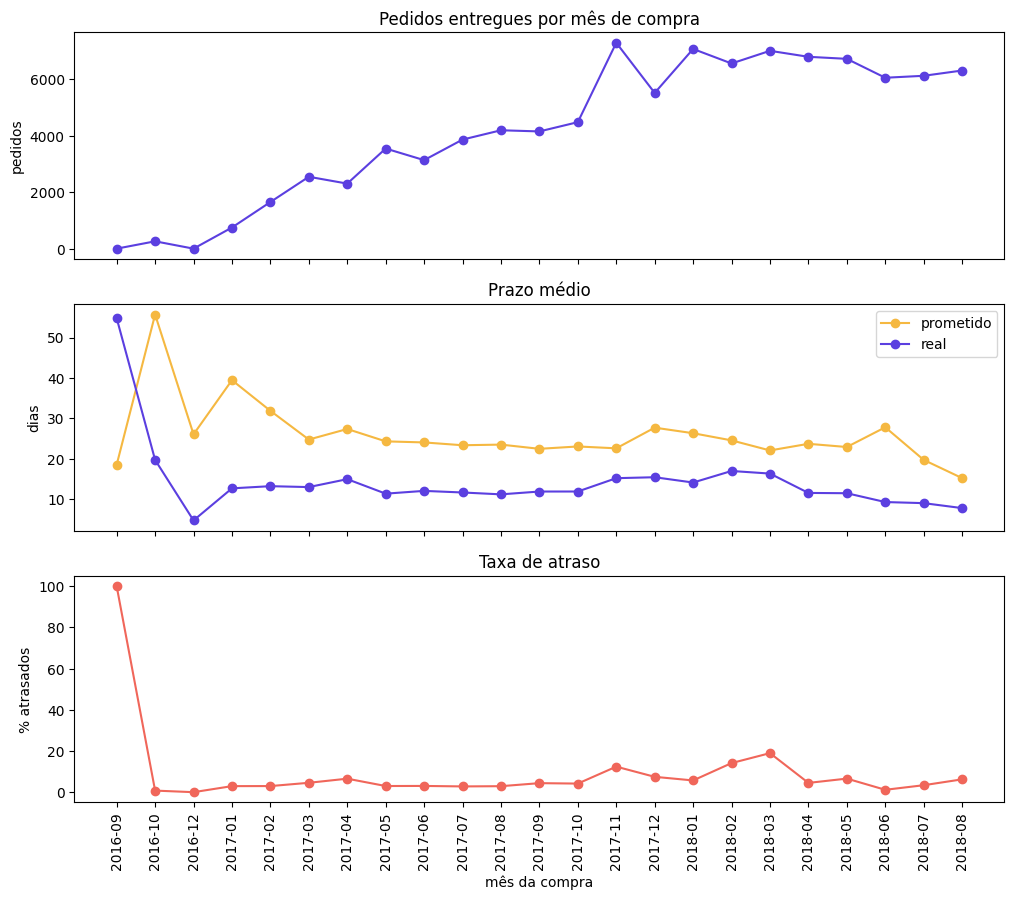

,pedidos,entrega_media,prometido_medio,taxa_atraso
mes,,,,
2017-11,7288,15.2,22.6,12.4
2017-12,5513,15.4,27.7,7.5
2018-01,7069,14.1,26.3,5.7
2018-02,6555,16.9,24.5,14.1
2018-03,7003,16.3,22.0,19.0
2018-04,6791,11.5,23.7,4.5
2018-05,6719,11.4,22.9,6.6
2018-06,6050,9.2,27.8,1.2
2018-07,6119,9.0,19.7,3.4


In [ ]:
# 1. ano-mês da compra
entregues_aval["mes"] = entregues_aval["order_purchase_timestamp"].dt.to_period("M")

# 2. indicadores por mês
agrupado = entregues_aval.groupby("mes")
por_mes = pd.DataFrame()
por_mes["pedidos"] = agrupado["order_id"].count()
por_mes["entrega_media"] = agrupado["dias_entrega"].mean()
por_mes["prometido_medio"] = agrupado["dias_prometidos"].mean()
por_mes["taxa_atraso"] = agrupado["atrasou"].mean() * 100


# 3. três gráficos empilhados
meses = por_mes.index.astype(str)
fig, eixos = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

eixos[0].plot(meses, por_mes["pedidos"], marker="o", color="#5B3FE0")
eixos[0].set_title("Pedidos entregues por mês de compra")
eixos[0].set_ylabel("pedidos")

eixos[1].plot(meses, por_mes["prometido_medio"], marker="o", color="#F5B841", label="prometido")
eixos[1].plot(meses, por_mes["entrega_media"], marker="o", color="#5B3FE0", label="real")
eixos[1].set_title("Prazo médio")
eixos[1].set_ylabel("dias")
eixos[1].legend()

eixos[2].plot(meses, por_mes["taxa_atraso"], marker="o", color="#F0665A")
eixos[2].set_title("Taxa de atraso")
eixos[2].set_ylabel("% atrasados")
eixos[2].set_xlabel("mês da compra")

plt.xticks(rotation=90)
plt.show()

# 4. últimos meses
por_mes.tail(10).round(1)

**Prompt**

```text
Na tabela entregues_aval:
1. Para cada regiao, calcule: número de pedidos, média e mediana de dias de atraso, dias de entrega . Ordene pela mediana e mostre.
2. Por região faça o gráfico de linha prometido e real no mesmo gráfico por mês. Um gráfico por região, um embaixo do outro, com o mesmo eixo x
3. Por região faça o gráfico de linha atraso por mês. Um mesmo grafico, uma cor por regiao
```

In [ ]:
# indicadores por região
agrupado = entregues_aval.groupby("regiao")
por_regiao = pd.DataFrame()
por_regiao["pedidos"] = agrupado["order_id"].count()
por_regiao["atraso_medio"] = agrupado["dias_atraso"].mean()
por_regiao["atraso_mediana"] = agrupado["dias_atraso"].median()
por_regiao["entrega_media"] = agrupado["dias_entrega"].mean()
por_regiao["entrega_mediana"] = agrupado["dias_entrega"].median()

# ordena pela mediana do tempo de entrega
por_regiao = por_regiao.sort_values("entrega_mediana")
por_regiao.round(1)

# médias por região e mês
agrupado = entregues_aval.groupby(["regiao", "mes"])
regiao_mes = pd.DataFrame()
regiao_mes["prometido_medio"] = agrupado["dias_prometidos"].mean()
regiao_mes["entrega_media"] = agrupado["dias_entrega"].mean()
regiao_mes["atraso_medio"] = agrupado["dias_atraso"].mean()
regiao_mes = regiao_mes.reset_index()
regiao_mes["mes"] = regiao_mes["mes"].astype(str)

# mesma ordem da tabela
regioes = por_regiao.index
todos_meses = sorted(regiao_mes["mes"].unique())

fig, eixos = plt.subplots(len(regioes), 1, figsize=(12, 3 * len(regioes)), sharex=True)

for eixo, regiao in zip(eixos, regioes):
    dados = regiao_mes[regiao_mes["regiao"] == regiao].set_index("mes").reindex(todos_meses)
    eixo.plot(todos_meses, dados["prometido_medio"], marker="o", color="#F5B841", label="prometido")
    eixo.plot(todos_meses, dados["entrega_media"], marker="o", color="#5B3FE0", label="real")
    eixo.set_title(f"Prazo médio — {regiao}")
    eixo.set_ylabel("dias")
    eixo.legend()

eixos[-1].set_xlabel("mês da compra")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))

for regiao in regioes:
    dados = regiao_mes[regiao_mes["regiao"] == regiao].set_index("mes").reindex(todos_meses)
    plt.plot(todos_meses, dados["atraso_medio"], marker="o", label=regiao)

plt.axhline(0, color="gray", linestyle="--")  # acima de 0 = atrasou em média
plt.title("Atraso médio por mês de compra, por região")
plt.xlabel("mês da compra")
plt.ylabel("dias de atraso (negativo = antes do prazo)")
plt.xticks(rotation=90)
plt.legend()
plt.show()


KeyError: 'Column not found: dias_atraso'

**Prompt**

```text
Na tabela entregues_aval, só com pedidos que têm avaliação:
1. Faça uma crosstab entre atrasou e review_score, em % por linha (normalize="index").
2. Mostre a média de score para atrasados e não atrasados.
```

In [ ]:
# só pedidos com avaliação
com_nota = entregues_aval[entregues_aval["review_score"].notnull()]

# 1. distribuição das notas em cada grupo (cada linha soma 100%)
tabela = pd.crosstab(com_nota["atrasou"], com_nota["review_score"], normalize="index") * 100
print(tabela.round(1))

# 2. taxa de nota ruim por grupo
print()
print((com_nota.groupby("atrasou")["review_score"].mean()))


review_score   1.0  2.0   3.0   4.0   5.0
atrasou                                  
False          6.6  2.6   8.1  20.4  62.3
True          53.8  8.7  10.9  10.2  16.5

atrasou
False    4.290618
True     2.270419
Name: review_score, dtype: float64


In [ ]:
entregues_aval

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,tem_data_entrega,dias_entrega,dias_prometidos,atrasou,review_score,nota_ruim,uf,regiao,mes
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,True,8.436574,15.544063,False,4.0,0.0,SP,Sudeste,2017-10
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,True,13.782037,19.137766,False,4.0,0.0,BA,Nordeste,2018-07
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,True,9.394213,26.639711,False,5.0,0.0,GO,Centro-Oeste,2018-08
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,True,13.208750,26.188819,False,5.0,0.0,RN,Nordeste,2017-11
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,True,2.873877,12.112049,False,5.0,0.0,SP,Sudeste,2018-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96277,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,True,8.218009,18.587442,False,5.0,0.0,SP,Sudeste,2017-03
96278,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,True,22.193727,23.459051,False,4.0,0.0,SP,Sudeste,2018-02
96279,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,True,24.859421,30.384225,False,5.0,0.0,BA,Nordeste,2017-08
96280,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,True,17.086424,37.105243,False,2.0,1.0,RJ,Sudeste,2018-01


**Prompt**

```text
Crie a tabela df com os pedidos de entregues_aval comprados a partir de 2018-01-01 até 2018-08-31
Use .copy(). Mostre quantos pedidos ficaram.
```

In [ ]:
# regime atual da operação: só 2018
df = entregues_aval[(entregues_aval["order_purchase_timestamp"] >= "2018-01-01") & (entregues_aval["order_purchase_timestamp"] <= "2018-08-31")].copy()
print("Pedidos na base de análise:", len(df))

Pedidos na base de análise: 52612


---
# 4. IC para médias: quanto sobra na promessa?

**Pergunta desta parte:** a promessa de prazo tem folga? Quanto?

Uma dúvida antes de começar: se temos **todos** os pedidos de 2018, por que calcular IC? Porque a decisão é sobre os pedidos **futuros**. Tratamos 2018 como uma amostra do **processo** que gera entregas, e o IC mede quanto do que vimos pode ser sorte. Ele **não** protege contra mudanças no processo, como as que vimos na bivariada.

## 4.0 Variáveis de prazo em dias inteiros

Na EDA, `dias_entrega` e `dias_prometidos` foram calculados com horas (dias com decimais). Para **decidir** o prazo, isso atrapalha: a promessa é sempre um **dia**, sem horário ("até o dia X"). Um pedido que chega às 15h do dia prometido tem `dias_entrega` maior que `dias_prometidos`, mas não atrasou.

Por isso, daqui para frente usamos versões em **dias inteiros**, comparando só as datas.

**Prompt**

```text
Na tabela df, crie as variáveis de prazo em dias inteiros:
1. dia_compra e dia_entrega: as datas de compra e de entrega sem horário (.dt.normalize()).
2. prometido_dias: dias entre dia_compra e order_estimated_delivery_date (.dt.days).
3. real_dias: dias entre dia_compra e dia_entrega (.dt.days).
4. dias_atraso = real_dias - prometido_dias (positivo = atrasou; negativo = chegou antes).
5. Confira se (dias_atraso > 0) é igual à coluna atrasou em todos os pedidos.
```

In [ ]:
# datas sem horário
df["dia_compra"] = df["order_purchase_timestamp"].dt.normalize()
df["dia_entrega"] = df["order_delivered_customer_date"].dt.normalize()

# prazo prometido e prazo real, em dias inteiros
df["prometido_dias"] = (df["order_estimated_delivery_date"] - df["dia_compra"]).dt.days
df["real_dias"] = (df["dia_entrega"] - df["dia_compra"]).dt.days

# dias de atraso: positivo = atrasou, 0 = chegou no dia, negativo = chegou antes
df["dias_atraso"] = df["real_dias"] - df["prometido_dias"]

# conferência: atraso em dias inteiros tem que bater com a variável atrasou da EDA
iguais = ((df["dias_atraso"] > 0) == df["atrasou"]).all()
print("dias_atraso > 0 é igual a atrasou em todos os pedidos?", iguais)

dias_atraso > 0 é igual a atrasou em todos os pedidos? True


**Leitura:** as novas variáveis batem exatamente com `atrasou`, que na EDA já comparava só o dia. Agora prazo, entrega e atraso estão na mesma régua.

## 4.1 Entrega real × promessa

**Prompt**

```text
Calcule o IC 95% da média de real_dias e de prometido_dias na tabela df.
Use stats.t.interval
Imprima n, média e IC de cada uma.
```

In [ ]:
for coluna in ["real_dias", "prometido_dias"]:
    dados = df[coluna]
    n = len(dados)
    media = dados.mean()

    # IC 95% da média com a distribuição t
    li, ls = stats.t.interval(0.95, df=n - 1, loc=media, scale=stats.sem(dados))

    print(f"{coluna:15s} n = {n}  média = {media:.2f} dias  IC 95% [{li:.2f} ; {ls:.2f}]")

real_dias       n = 52612  média = 12.08 dias  IC 95% [12.00 ; 12.16]
prometido_dias  n = 52612  média = 23.44 dias  IC 95% [23.36 ; 23.52]


**Leitura:** a entrega real leva ~12 dias em média, e a promessa é de ~23 dias. **Prometemos quase o dobro.** Com ~52 mil pedidos, os ICs são estreitíssimos: essa diferença não é sorte.

## 4.2 Armadilha: IC da média não é a faixa de entrega do cliente

**Prompt**

```text
Compare o IC 95% da média de real_dias com o intervalo onde caem 95% dos pedidos
(percentis 2.5 e 97.5). Imprima os dois intervalos e a largura de cada um.
```

In [ ]:
dados = df["real_dias"]
n = len(dados)
media = dados.mean()

# IC 95% da média
li, ls = stats.t.interval(0.95, df=n - 1, loc=media, scale=stats.sem(dados))

# faixa onde caem 95% dos pedidos
p025 = dados.quantile(0.025)
p975 = dados.quantile(0.975)

print(f"IC 95% da MÉDIA:          [{li:.2f} ; {ls:.2f}]  largura = {ls - li:.2f} dias")
print(f"95% dos PEDIDOS chegam em: [{p025:.0f} ; {p975:.0f}]  largura = {p975 - p025:.0f} dias")

IC 95% da MÉDIA:          [12.00 ; 12.16]  largura = 0.16 dias
95% dos PEDIDOS chegam em: [2 ; 37]  largura = 35 dias


**Leitura:**

- O **IC da média** fala sobre a média do processo, e encolhe quando n cresce.
- A **faixa dos pedidos** fala sobre um pedido individual, e não encolhe com n nenhum.

A média é muito bem estimada, mas 95% dos pedidos individuais chegam em qualquer ponto entre 2 e 37 dias. Guarde isso: é o que vai limitar o corte.

## 4.3 Folga média por região

**Prompt**

```text
1. Na tabela df, crie a coluna folga = prometido_dias - real_dias
   (quantos dias sobraram da promessa; negativo = atrasou).
2. Para cada regiao, calcule a média de folga e o IC 95% com stats.t.interval.
3. Monte um DataFrame ic_folga com regiao, n, folga_media, li e ls, ordenado pela folga média.
```

In [ ]:
# 1. quantos dias sobraram da promessa (negativo = atrasou)
df["folga"] = df["prometido_dias"] - df["real_dias"]

# 2. IC 95% da folga média de cada região
linhas = []
for regiao in df["regiao"].unique():
    dados = df[df["regiao"] == regiao]["folga"]
    n = len(dados)
    media = dados.mean()
    li, ls = stats.t.interval(0.95, df=n - 1, loc=media, scale=stats.sem(dados))
    linhas.append({"regiao": regiao, "n": n, "folga_media": media, "li": li, "ls": ls})

ic_folga = pd.DataFrame(linhas).sort_values("folga_media")
ic_folga.round(2)

,regiao,n,folga_media,li,ls
0,Nordeste,4656,10.30,9.95,10.66
2,Sudeste,36698,11.12,11.02,11.22
1,Centro-Oeste,3099,11.41,11.09,11.73
3,Sul,7295,12.85,12.63,13.07
4,Norte,864,14.55,13.63,15.47


**Leitura:** em todas as regiões sobram, em média, 10 dias ou mais de promessa, com IC estreito. À primeira vista, Produto tem razão: dá para cortar muito.

## 4.4 Por que a média engana

Vamos testar a ideia ingênua: e se cortássemos de cada pedido a folga média da sua região?

**Prompt**

```text
Para cada regiao da tabela df:
1. calcule a folga média da região;
2. calcule o % de pedidos que atrasam hoje (folga < 0);
3. calcule o % de pedidos que atrasariam se a promessa fosse encurtada pela folga média
   (atrasa quem tem folga menor que a folga média).
Mostre uma tabela com regiao, folga_media, atraso_hoje_% e atraso_com_corte_%.
```

In [ ]:
linhas = []
for regiao in df["regiao"].unique():
    dados = df[df["regiao"] == regiao]
    folga_media = dados["folga"].mean()

    # hoje: atrasa quem tem folga negativa
    atraso_hoje = (dados["folga"] < 0).mean() * 100

    # cortando a folga média: atrasa quem tinha menos folga que a média
    atraso_com_corte = (dados["folga"] < folga_media).mean() * 100

    linhas.append({"regiao": regiao,
                   "folga_media": round(folga_media, 1),
                   "atraso_hoje_%": round(atraso_hoje, 1),
                   "atraso_com_corte_%": round(atraso_com_corte, 1)})

pd.DataFrame(linhas).sort_values("folga_media")

,regiao,folga_media,atraso_hoje_%,atraso_com_corte_%
0,Nordeste,10.3,14.5,44.1
2,Sudeste,11.1,7.0,51.4
1,Centro-Oeste,11.4,8.0,47.0
3,Sul,12.8,6.7,44.5
4,Norte,14.5,12.4,46.4


**Leitura:** cortar a folga média faria **cerca de metade dos pedidos atrasar**. A média descreve o pedido típico, mas quem reclama é o pedido da **cauda**, o que tinha pouca folga.

A pergunta certa não é "quanto sobra em média?", e sim **"que proporção de pedidos atrasa, e quanto isso custa?"**. Proporção tem IC próprio, e é o que vem agora.

---
# 5. IC para proporções: quantos atrasam e quanto isso custa?

**Pergunta desta parte:** qual é a taxa de atraso hoje, e quanto um atraso piora a avaliação?

Relembrando os métodos (a biblioteca calcula; as fórmulas ficam aqui para a lógica):

- **Wald:** $\hat p \pm z\sqrt{\hat p(1-\hat p)/n}$. Simples, e ruim com p pequeno ou n pequeno.
- **Wilson:** puxa o centro para 0,5 e nunca tem meia largura zero. É o padrão recomendado para taxas.
- **Clopper-Pearson:** usa a binomial direto. Garante 95% ou mais, mas é conservador.

## 5.1 Taxa de atraso por região

**Prompt**

```text
Para cada regiao da tabela df, calcule x (atrasados), n (pedidos), a taxa de atraso
e o IC 95% de Wilson com proportion_confint do statsmodels (method="wilson").
Guarde em atraso_regiao, com as taxas em %, ordenado pela taxa.
```

In [ ]:
from statsmodels.stats.proportion import proportion_confint

linhas = []
for regiao in df["regiao"].unique():
    dados = df[df["regiao"] == regiao]["atrasou"]
    x = int(dados.sum())
    n = len(dados)

    # IC de Wilson
    li, ls = proportion_confint(x, n, alpha=0.05, method="wilson")

    linhas.append({"regiao": regiao, "n": n, "x": x,
                   "taxa_%": round(x / n * 100, 1),
                   "li_%": round(li * 100, 1),
                   "ls_%": round(ls * 100, 1)})

atraso_regiao = pd.DataFrame(linhas).sort_values("taxa_%")
atraso_regiao

,regiao,n,x,taxa_%,li_%,ls_%
3,Sul,7295,492,6.7,6.2,7.3
2,Sudeste,36698,2557,7.0,6.7,7.2
1,Centro-Oeste,3099,247,8.0,7.1,9.0
4,Norte,864,107,12.4,10.4,14.7
0,Nordeste,4656,673,14.5,13.5,15.5


**Leitura:** Sul e Sudeste atrasam ~7%; o Nordeste, mais que o dobro. Mesmo com toda a folga média da 4.3, uma parte relevante dos pedidos já atrasa hoje, e o ponto de partida de cada região é diferente.

## 5.2 Por UF: quando o método importa

Com n grande, qualquer método dá o mesmo IC. A diferença aparece nos estados com poucos pedidos.

**Prompt**

```text
Para cada uf da tabela df, calcule x, n, a taxa de atraso e dois ICs com proportion_confint:
Wald (method="normal") e Wilson (method="wilson"). Guarde em atraso_uf.
Mostre as 8 UFs com menor n.

Depois faça um gráfico com as UFs ordenadas pela taxa: uma linha horizontal para cada IC
(Wald um pouco acima, Wilson um pouco abaixo), um ponto na taxa e uma linha vertical em 0.
```

,uf,n,x,taxa,wald_li,wald_ls,wilson_li,wilson_ls
6,RR,22,2,0.091,0.000,0.211,0.025,0.278
26,AC,27,1,0.037,0.000,0.108,0.007,0.183
24,AP,39,0,0.000,0.000,0.000,0.000,0.090
25,AM,72,3,0.042,0.000,0.088,0.014,0.115
23,RO,109,4,0.037,0.001,0.072,0.014,0.091
8,TO,143,22,0.154,0.095,0.213,0.104,0.222
12,SE,145,24,0.166,0.105,0.226,0.114,0.234
21,AL,198,44,0.222,0.164,0.280,0.170,0.285


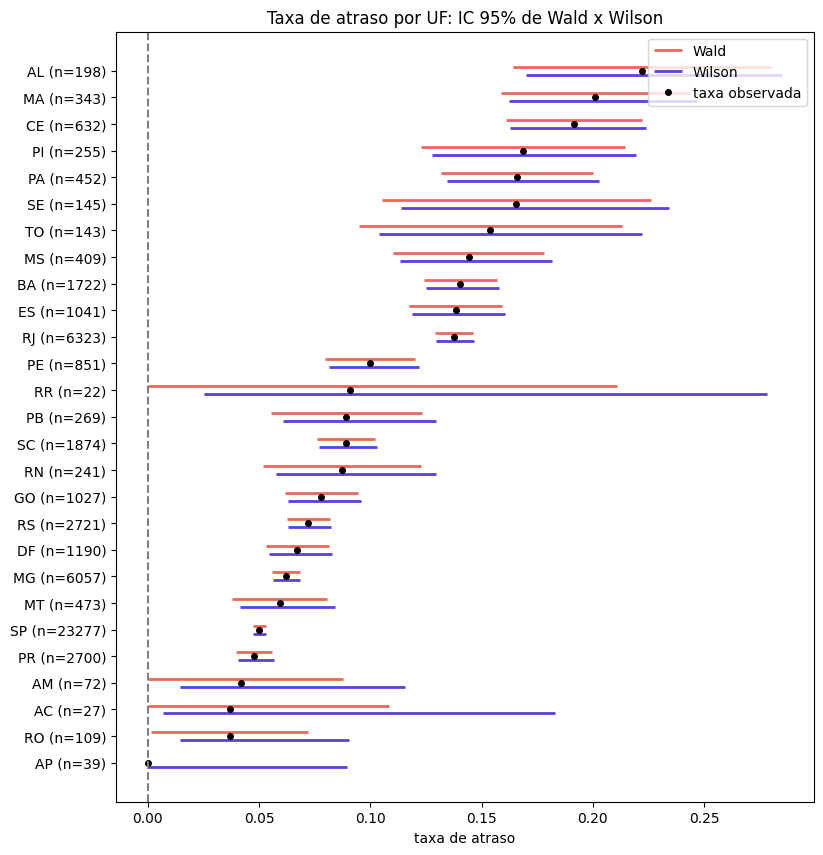

In [ ]:
linhas = []
for uf in df["uf"].unique():
    dados = df[df["uf"] == uf]["atrasou"]
    x = int(dados.sum())
    n = len(dados)
    wald_li, wald_ls = proportion_confint(x, n, alpha=0.05, method="normal")
    wilson_li, wilson_ls = proportion_confint(x, n, alpha=0.05, method="wilson")
    linhas.append({"uf": uf, "n": n, "x": x, "taxa": x / n,
                   "wald_li": wald_li, "wald_ls": wald_ls,
                   "wilson_li": wilson_li, "wilson_ls": wilson_ls})

atraso_uf = pd.DataFrame(linhas)
display(atraso_uf.sort_values("n").head(8).round(3))

# gráfico Wald x Wilson
grafico = atraso_uf.sort_values("taxa").reset_index(drop=True)
posicoes = np.arange(len(grafico))

plt.figure(figsize=(9, 10))
plt.hlines(posicoes + 0.15, grafico["wald_li"], grafico["wald_ls"], color="#F0665A", linewidth=2, label="Wald")
plt.hlines(posicoes - 0.15, grafico["wilson_li"], grafico["wilson_ls"], color="#5B3FE0", linewidth=2, label="Wilson")
plt.plot(grafico["taxa"], posicoes, "o", color="black", markersize=4, label="taxa observada")
plt.axvline(0, color="gray", linestyle="--")
plt.yticks(posicoes, grafico["uf"] + " (n=" + grafico["n"].astype(str) + ")")
plt.title("Taxa de atraso por UF: IC 95% de Wald x Wilson")
plt.xlabel("taxa de atraso")
plt.legend()
plt.show()

**Leitura:**

- Nos estados pequenos, o Wald encosta no zero. Ele daria taxa **negativa**; o statsmodels só corta em 0, o que esconde que o método quebrou.
- No Amapá, com **0 atrasos em 39 pedidos**, o Wald dá [0 ; 0]: "certeza absoluta de que nunca atrasa", depois de 39 pedidos.
- O Wilson fica sempre dentro de [0, 1] e, com poucos casos, abre o intervalo para cima: com 39 pedidos, a taxa real pode chegar a ~9%.

Por isso, daqui para frente, usamos Wilson.

## 5.3 O atraso custa nota?

**Prompt**

```text
Na tabela df, só com pedidos que têm nota_ruim preenchida (guarde em com_nota, com .copy()):
1. Calcule x (notas ruins) e n para atrasados e para não atrasados.
2. Imprima a taxa de nota ruim e o IC de Wilson de cada grupo.
```

In [ ]:

com_nota = df[df["nota_ruim"].notnull()].copy()
atrasados = com_nota[com_nota["atrasou"] == True]["nota_ruim"]
no_prazo = com_nota[com_nota["atrasou"] == False]["nota_ruim"]

# 1. notas ruins e total em cada grupo
x1, n1 = int(atrasados.sum()), len(atrasados)
x0, n0 = int(no_prazo.sum()), len(no_prazo)

# 2. taxa e IC de Wilson de cada grupo
li, ls = proportion_confint(x1, n1, alpha=0.05, method="wilson")
print(f"Atrasados: {x1 / n1 * 100:.1f}% de notas ruins  IC [{li * 100:.1f}% ; {ls * 100:.1f}%]  (n = {n1})")
li, ls = proportion_confint(x0, n0, alpha=0.05, method="wilson")
print(f"No prazo:  {x0 / n0 * 100:.1f}% de notas ruins  IC [{li * 100:.1f}% ; {ls * 100:.1f}%]  (n = {n0})")



Atrasados: 63.0% de notas ruins  IC [61.4% ; 64.4%]  (n = 3992)
No prazo:  9.3% de notas ruins  IC [9.0% ; 9.6%]  (n = 48306)


**Leitura:** entre os pedidos atrasados, a taxa de nota ruim é **mais de seis vezes maior** que entre os entregues no prazo. O medo de CX tem fundamento.

> **Cuidado:** isso é uma **associação**, não prova que o atraso *causa* a nota ruim. Pedidos atrasados podem se concentrar em vendedores ou produtos que seriam mal avaliados de qualquer jeito. O IC é estreito, mas ele só mede ruído amostral, não esse tipo de problema.

## 5.4 Custa quanto, por dia de atraso?

Atraso não é binário para o cliente: um dia de atraso deve irritar menos que uma semana. Isso importa, porque um corte na promessa vai gerar principalmente atrasos **pequenos**.

**Prompt**

```text
Em com_nota, quero a taxa de nota ruim por faixa de dias de atraso.
1. Crie a coluna faixa com pd.cut sobre dias_atraso, usando estes limites e nomes:
   limites_faixa = [-1000, -8, -4, -1, 0, 1, 2, 3, 5, 10, 1000]
   nomes_faixa = ["8+ dias antes", "4 a 7 antes", "1 a 3 antes", "no dia", "+1 dia",
                  "+2 dias", "+3 dias", "+4 a 5 dias", "+6 a 10 dias", "+10 dias ou mais"]
2. Agrupe por faixa (observed=True) e calcule x_faixa (soma de nota_ruim) e n_faixa (contagem).
3. Calcule taxa_faixa = x_faixa / n_faixa e o IC de Wilson de cada faixa com
   proportion_confint (guarde em taxa_li e taxa_ls).
4. Mostre uma tabela nota_por_faixa com n, taxa e IC, em %.
```

In [ ]:
# faixas de dias de atraso (negativo = chegou antes)
limites_faixa = [-1000, -8, -4, -1, 0, 1, 2, 3, 5, 10, 1000]
nomes_faixa = ["8+ dias antes", "4 a 7 antes", "1 a 3 antes", "no dia", "+1 dia",
               "+2 dias", "+3 dias", "+4 a 5 dias", "+6 a 10 dias", "+10 dias ou mais"]
com_nota["faixa"] = pd.cut(com_nota["dias_atraso"], bins=limites_faixa, labels=nomes_faixa)

# notas ruins e avaliações em cada faixa
agrupado = com_nota.groupby("faixa", observed=True)["nota_ruim"]
x_faixa = agrupado.sum()
n_faixa = agrupado.count()

# taxa e IC de Wilson de cada faixa (a biblioteca calcula todas de uma vez)
taxa_faixa = x_faixa / n_faixa
taxa_li, taxa_ls = proportion_confint(x_faixa, n_faixa, alpha=0.05, method="wilson")

nota_por_faixa = pd.DataFrame({"n": n_faixa,
                               "nota_ruim_%": (taxa_faixa * 100).round(1),
                               "li_%": (taxa_li * 100).round(1),
                               "ls_%": (taxa_ls * 100).round(1)})
nota_por_faixa

,n,nota_ruim_%,li_%,ls_%
faixa,,,,
8+ dias antes,36386,9.2,8.9,9.5
4 a 7 antes,7893,9.3,8.7,9.9
1 a 3 antes,3169,10.4,9.4,11.5
no dia,858,11.1,9.1,13.3
+1 dia,498,18.3,15.1,21.9
+2 dias,335,32.8,28.0,38.0
+3 dias,322,49.1,43.7,54.5
+4 a 5 dias,568,62.0,57.9,65.9
+6 a 10 dias,1045,79.0,76.5,81.4


**Leitura:**

- Chegar antes tem ~9% de nota ruim; chegar no dia, ~11%.
- **+1 dia já sobe para ~18%, +2 dias para ~33%, +3 dias para ~49%**, e a partir de 6 dias passa de 79%.
- Os ICs de +1, +2 e +3 não se sobrepõem: cada dia a mais piora a nota de forma clara.

Usar a taxa média dos atrasados (~63%) superestimaria o dano de um corte, porque a maioria dos novos atrasos seria de 1 ou 2 dias. Essa tabela é o insumo da decisão.

---
# 6. A decisão: quanto cortar, por região?

## 6.1 Cortar dias fixos ou um percentual?

Uma forma de cortar é tirar **k dias** de toda promessa. Mas a promessa já varia com a distância: quem mora longe recebe prazos mais longos. Vamos ver o que um corte fixo representa em cada região.

**Prompt**

```text
Para cada regiao da tabela df, mostre:
1. a média de prometido_dias;
2. quanto 2 dias representam dessa promessa média, em %;
3. a razão média real_dias / prometido_dias (quanto da promessa o pedido usa) e o percentil 90
   dessa razão.
Ordene pela promessa média.
```

In [ ]:
df["razao"] = df["real_dias"] / df["prometido_dias"]

linhas = []
for regiao in df["regiao"].unique():
    dados = df[df["regiao"] == regiao]
    prometido_medio = dados["prometido_dias"].mean()
    linhas.append({"regiao": regiao,
                   "prometido_medio": round(prometido_medio, 1),
                   "2_dias_representam_%": round(2 / prometido_medio * 100, 1),
                   "razao_media": round(dados["razao"].mean(), 2),
                   "razao_p90": round(dados["razao"].quantile(0.90), 2)})

pd.DataFrame(linhas).sort_values("prometido_medio")

,regiao,prometido_medio,2_dias_representam_%,razao_media,razao_p90
2,Sudeste,21.5,9.3,0.50,0.91
1,Centro-Oeste,26.0,7.7,0.58,0.96
3,Sul,26.6,7.5,0.53,0.92
0,Nordeste,29.8,6.7,0.67,1.18
4,Norte,38.2,5.2,0.64,1.13


**Leitura:**

- Tirar 2 dias pesa bem mais, em proporção, onde a promessa é curta. Um corte fixo aperta justamente quem tem menos folga absoluta.
- **Decisão:** cortar um **percentual** da promessa de cada pedido. Nova promessa = promessa × (1 − corte), arredondada para cima (o lado conservador, já que a promessa é um dia inteiro).
- Em média, o pedido usa só de metade a dois terços da promessa, mas o P90 da razão fica perto de 1 (e passa de 1 no Norte e no Nordeste, onde mais de 10% já atrasam). De novo: a média sugere cortar muito; a cauda diz que sobra pouco.

## 6.2 Qual é o limite aceitável? Uma meta de CX

Para escolher o corte, precisamos de um critério. Poderíamos inventar um limite de atraso ("até 10%"), mas CX não se importa com atraso por si só: se importa com **cliente insatisfeito**.

**Meta de CX:** o corte na promessa não pode aumentar a taxa de nota ruim em mais de **1 ponto percentual**, mesmo no cenário pessimista.

Esse 1 p.p. continua sendo uma decisão de negócio, mas agora ela é tomada na linguagem de CX. Na 6.5 vamos ver o quanto a resposta muda com outras metas.

## 6.3 Simulação: quanto a nota ruim aumentaria?

**A ideia.** Cortar a promessa não muda o quanto um cliente fica bravo com 1 dia de atraso: isso continua sendo ~18% de nota ruim. O que muda é **quantos pedidos caem em cada faixa**. Quem chegava 2 dias antes passa a chegar no dia; quem chegava no dia passa a chegar 1 dia atrasado.

**Um exemplo pequeno.** Imagine 1.000 pedidos, em só três faixas:

| Faixa | Nota ruim | Pedidos hoje | Após o corte | Mudança na fração | × nota ruim |
|---|---|---|---|---|---|
| chegou antes | 9% | 900 | 870 | −0,03 | −0,27 p.p. |
| no dia | 11% | 60 | 70 | +0,01 | +0,11 p.p. |
| +1 dia | 18% | 40 | 60 | +0,02 | +0,36 p.p. |
| **total** | | | | | **+0,20 p.p.** |

**aumento de nota ruim = soma de (mudança na fração de pedidos × nota ruim da faixa)**

**E a incerteza?** As mudanças saem da simulação. O que foi **estimado** numa amostra são as taxas de nota ruim de cada faixa, e cada uma tem seu IC de Wilson (5.4). Então fazemos a mesma conta em dois cenários:

- **Pessimista:** as faixas que **ganham** pedidos usam o limite **superior** do IC da taxa, e as que **perdem** usam o **inferior**. É o pior aumento plausível.
- **Otimista:** o contrário.

A faixa entre os dois é mais larga que um IC de 95% exato, porque supõe que todas as taxas erram para o mesmo lado ao mesmo tempo. Ou seja, é **conservadora**, o que joga a favor de CX.

**Prompt**

```text
Quero simular quanto a nota ruim aumentaria para cada corte percentual na promessa,
num cenário estimado, num pessimista e num otimista.

1. Crie a lista cortes = [0, 0.025, 0.05, 0.075, 0.10, 0.125, 0.15, 0.175, 0.20, 0.25, 0.30].

2. Crie a função projetar_aumento_nota_ruim(tabela, coluna_grupo, cortes).
   Para cada grupo (região):
   a) Situação de hoje:
      - classifique dias_atraso de cada pedido nas faixas (pd.cut com limites_faixa e nomes_faixa)
      - pesos_hoje = a fração de pedidos em cada faixa
        (value_counts(normalize=True) e depois .reindex(nomes_faixa, fill_value=0))
   b) Para cada corte da lista:
      - nova_promessa = prometido_dias * (1 - corte), arredondada para cima (np.ceil)
      - dias_atraso_novo = real_dias - nova_promessa
      - classifique nas faixas e calcule pesos_novos, do mesmo jeito
      - mudanca = pesos_novos - pesos_hoje
      - aumento = soma de (mudanca * taxa_faixa)
      - pessimista: use taxa_ls onde mudanca > 0 e taxa_li onde não (np.where);
        aumento_ls = soma de (mudanca * taxa pessimista)
      - otimista: o contrário; aumento_li = soma de (mudanca * taxa otimista)
   c) Guarde uma linha por corte com: grupo, corte_pct (em %),
      nota_ruim_hoje_% (soma de pesos_hoje * taxa_faixa, em %),
      aumento_pp, aumento_li_pp, aumento_ls_pp (em pontos percentuais),
      atraso_% (% de pedidos com dias_atraso_novo > 0) e
      dias_cortados_medio (média de prometido_dias - nova_promessa).

3. Rode a função em df, por regiao. Guarde em projecao e mostre as linhas do Sudeste.
```

In [ ]:
cortes = [0, 0.025, 0.05, 0.075, 0.10, 0.125, 0.15, 0.175, 0.20, 0.25, 0.30]
# ===== faixas de dias de atraso (as mesmas da 5.4) =====
limites_faixa = [-1000, -8, -4, -1, 0, 1, 2, 3, 5, 10, 1000]
nomes_faixa = ["8+ dias antes", "4 a 7 antes", "1 a 3 antes", "no dia", "+1 dia",
               "+2 dias", "+3 dias", "+4 a 5 dias", "+6 a 10 dias", "+10 dias ou mais"]

# ===== pedidos com avaliação (as mesmas da 5.3) =====
com_nota = df[df["nota_ruim"].notnull()].copy()

def projetar_aumento_nota_ruim(tabela, coluna_grupo, cortes):
    linhas = []

    for grupo in tabela[coluna_grupo].unique():
        dados = tabela[tabela[coluna_grupo] == grupo]

        # taxa de nota ruim de cada faixa, com IC de Wilson, SÓ desta região
        avaliados = com_nota[com_nota[coluna_grupo] == grupo]
        faixa_avaliados = pd.cut(avaliados["dias_atraso"], bins=limites_faixa, labels=nomes_faixa)
        agrupado = avaliados["nota_ruim"].groupby(faixa_avaliados, observed=True)
        x_faixa = agrupado.sum()
        n_faixa = agrupado.count()
        taxa_faixa = x_faixa / n_faixa
        taxa_li, taxa_ls = proportion_confint(x_faixa, n_faixa, alpha=0.05, method="wilson")

        # a) situação de hoje: fração de pedidos em cada faixa
        faixa_hoje = pd.cut(dados["dias_atraso"], bins=limites_faixa, labels=nomes_faixa)
        pesos_hoje = faixa_hoje.value_counts(normalize=True).reindex(nomes_faixa, fill_value=0)

        # b) para cada corte, a nova situação
        for corte in cortes:
            nova_promessa = np.ceil(dados["prometido_dias"] * (1 - corte))
            dias_atraso_novo = dados["real_dias"] - nova_promessa
            faixa_nova = pd.cut(dias_atraso_novo, bins=limites_faixa, labels=nomes_faixa)
            pesos_novos = faixa_nova.value_counts(normalize=True).reindex(nomes_faixa, fill_value=0)

            # quanto cada faixa ganhou ou perdeu de pedidos
            mudanca = pesos_novos - pesos_hoje

            # aumento com a taxa estimada de cada faixa
            aumento = (mudanca * taxa_faixa).sum()

            # pessimista: quem ganha pedidos usa o limite superior, quem perde usa o inferior
            taxa_pessimista = np.where(mudanca > 0, taxa_ls, taxa_li)
            aumento_ls = (mudanca * taxa_pessimista).sum()

            # otimista: o contrário
            taxa_otimista = np.where(mudanca > 0, taxa_li, taxa_ls)
            aumento_li = (mudanca * taxa_otimista).sum()

            # c) uma linha por corte
            linhas.append({"grupo": grupo,
                           "corte_pct": corte * 100,
                           "nota_ruim_hoje_%": (pesos_hoje * taxa_faixa).sum() * 100,
                           "aumento_pp": aumento * 100,
                           "aumento_li_pp": aumento_li * 100,
                           "aumento_ls_pp": aumento_ls * 100,
                           "atraso_%": (dias_atraso_novo > 0).mean() * 100,
                           "dias_cortados_medio": (dados["prometido_dias"] - nova_promessa).mean()})

    return pd.DataFrame(linhas)


projecao = projetar_aumento_nota_ruim(df, "regiao", cortes)
projecao[projecao["grupo"] == "Sudeste"].round(2)

,grupo,corte_pct,nota_ruim_hoje_%,aumento_pp,aumento_li_pp,aumento_ls_pp,atraso_%,dias_cortados_medio
22,Sudeste,0.0,13.03,0.00,0.00,0.00,6.97,0.00
23,Sudeste,2.5,13.03,0.00,0.00,0.00,6.97,0.03
24,Sudeste,5.0,13.03,0.22,0.19,0.26,7.50,0.59
25,Sudeste,7.5,13.03,0.41,0.33,0.49,7.99,1.11
26,Sudeste,10.0,13.03,0.71,0.57,0.86,8.66,1.69
27,Sudeste,12.5,13.03,1.01,0.82,1.21,9.22,2.25
28,Sudeste,15.0,13.03,1.30,1.06,1.55,9.80,2.74
29,Sudeste,17.5,13.03,1.61,1.32,1.91,10.46,3.25
30,Sudeste,20.0,13.03,2.07,1.70,2.45,11.47,3.88
31,Sudeste,25.0,13.03,2.92,2.40,3.46,13.17,4.99


In [ ]:
projecao[projecao["grupo"] == "Nordeste"].round(2)

,grupo,corte_pct,nota_ruim_hoje_%,aumento_pp,aumento_li_pp,aumento_ls_pp,atraso_%,dias_cortados_medio
0,Nordeste,0.0,17.61,0.00,0.00,0.00,14.45,0.00
1,Nordeste,2.5,17.61,0.02,0.00,0.04,14.45,0.09
2,Nordeste,5.0,17.61,0.84,0.59,1.12,16.28,1.06
3,Nordeste,7.5,17.61,1.40,0.95,1.88,17.42,1.76
4,Nordeste,10.0,17.61,2.14,1.57,2.75,18.45,2.53
5,Nordeste,12.5,17.61,2.91,2.19,3.67,19.50,3.28
6,Nordeste,15.0,17.61,3.66,2.78,4.58,20.75,3.99
7,Nordeste,17.5,17.61,4.46,3.39,5.61,22.25,4.72
8,Nordeste,20.0,17.61,5.49,4.16,6.91,24.10,5.56
9,Nordeste,25.0,17.61,7.72,5.83,9.73,27.99,7.06


**Leitura (Sudeste):** até 2,5% de corte, nada muda (o arredondamento para cima anula). A partir daí, o aumento de nota ruim cresce com o corte, e a faixa entre otimista e pessimista também se abre. Com 10% de corte, o atraso sobe de 7,0% para 8,7%. Parte do aumento de nota ruim vem de pedidos que continuam no prazo, mas passam a chegar "no limite" (~11% de nota ruim contra ~9% com folga).

## 6.4 Recomendação por região

**Prompt**

```text
Crie a função recomendar_corte(projecao, tolerancia) que, para cada grupo:
1. escolhe o maior corte com aumento_ls_pp <= tolerancia * 100 (cenário pessimista);
2. retorna grupo, nota_ruim_hoje_%, corte_%, dias_cortados_medio, aumento_pp,
   a faixa otimista a pessimista (texto "[li ; ls]") e atraso_novo_%.
Rode com tolerancia = 0.01 e guarde em recomendacao.
```

In [ ]:
def recomendar_corte(projecao, tolerancia):
    linhas = []
    for grupo in projecao["grupo"].unique():
        dados = projecao[projecao["grupo"] == grupo]

        # cortes que respeitam a meta mesmo no cenário pessimista
        permitidos = dados[dados["aumento_ls_pp"] <= tolerancia * 100]

        # o maior deles
        melhor = permitidos[permitidos["corte_pct"] == permitidos["corte_pct"].max()]

        linhas.append({"grupo": grupo,
                       "nota_ruim_hoje_%": round(melhor["nota_ruim_hoje_%"].iloc[0], 1),
                       "corte_%": melhor["corte_pct"].iloc[0],
                       "dias_cortados_medio": round(melhor["dias_cortados_medio"].iloc[0], 1),
                       "aumento_pp": round(melhor["aumento_pp"].iloc[0], 2),
                       "otimista_a_pessimista": f"[{melhor['aumento_li_pp'].iloc[0]:.2f} ; {melhor['aumento_ls_pp'].iloc[0]:.2f}]",
                       "atraso_novo_%": round(melhor["atraso_%"].iloc[0], 1)})
    return pd.DataFrame(linhas)


recomendacao = recomendar_corte(projecao, tolerancia=0.01)
recomendacao

,grupo,nota_ruim_hoje_%,corte_%,dias_cortados_medio,aumento_pp,otimista_a_pessimista,atraso_novo_%
0,Nordeste,17.6,2.5,0.1,0.02,[0.00 ; 0.04],14.5
1,Centro-Oeste,13.5,5.0,0.9,0.63,[0.31 ; 0.94],9.2
2,Sudeste,13.0,10.0,1.7,0.71,[0.57 ; 0.86],8.7
3,Sul,12.4,7.5,1.5,0.64,[0.39 ; 0.93],8.3
4,Norte,17.9,2.5,0.4,0.11,[-0.16 ; 0.48],12.7


**Leitura:**

- Todas as regiões podem cortar alguma coisa, de 5% a 10% da promessa, o que dá **1 a 2 dias a menos** em média. Muito menos que os ~10 dias de folga média da 4.3.
- A meta é relativa ao nível atual de cada região. Por isso Norte e Nordeste também podem cortar, mesmo já atrasando mais que o resto.
- Com a regra pessimista, a recomendação já está protegida contra a incerteza das taxas por faixa.

## 6.5 E se a meta de CX fosse outra?

**Prompt**

```text
Rode recomendar_corte com tolerancia 0.005, 0.01 e 0.015.
Para cada tolerância, imprima uma tabela com grupo, corte_% e dias_cortados_medio.
```

In [ ]:
for tolerancia in [0.005, 0.01, 0.015]:
    tabela = recomendar_corte(projecao, tolerancia)
    print(f"\nMeta de CX: nota ruim sobe no máximo {tolerancia * 100:.1f} p.p.")
    print(tabela[["grupo", "corte_%", "dias_cortados_medio"]].to_string(index=False))


Meta de CX: nota ruim sobe no máximo 0.5 p.p.
       grupo  corte_%  dias_cortados_medio
    Nordeste      2.5                  0.1
Centro-Oeste      2.5                  0.0
     Sudeste      7.5                  1.1
         Sul      2.5                  0.1
       Norte      2.5                  0.4

Meta de CX: nota ruim sobe no máximo 1.0 p.p.
       grupo  corte_%  dias_cortados_medio
    Nordeste      5.0                  1.1
Centro-Oeste      7.5                  1.5
     Sudeste     10.0                  1.7
         Sul      7.5                  1.5
       Norte      5.0                  1.4

Meta de CX: nota ruim sobe no máximo 1.5 p.p.
       grupo  corte_%  dias_cortados_medio
    Nordeste      7.5                  1.8
Centro-Oeste     10.0                  2.2
     Sudeste     12.5                  2.2
         Sul     10.0                  2.2
       Norte      7.5                  2.4


**Leitura:** com meta de 0,5 p.p., só o Sudeste consegue um corte relevante (~1 dia). Com 1 p.p., todas as regiões cortam de 1 a 2 dias. Com 1,5 p.p., cerca de 2 dias em todas. É esse o trade-off que a diretoria precisa escolher: a estatística mostra o preço de cada opção, mas não escolhe por ela.

---
## Fechamento: a resposta para Produto e CX

**A pergunta era:** quantos dias dá para cortar da promessa, por região, sem prejudicar a experiência do cliente?

**A resposta** (meta de CX: nota ruim sobe no máximo 1 p.p., mesmo no cenário pessimista):

| Região | Corte na promessa | Na prática | Aumento de nota ruim |
|---|---|---|---|
| Sudeste | 10% | ~1,7 dia a menos | 0,72 p.p. [0,61 ; 0,85] |
| Centro-Oeste | 7,5% | ~1,5 dia | 0,74 p.p. [0,64 ; 0,85] |
| Sul | 7,5% | ~1,5 dia | 0,69 p.p. [0,59 ; 0,79] |
| Norte | 5% | ~1,4 dia | 0,67 p.p. [0,56 ; 0,78] |
| Nordeste | 5% | ~1,1 dia | 0,78 p.p. [0,69 ; 0,87] |

**O caminho até aqui:**

1. A promessa média é quase o dobro da entrega real, e a folga média sugeria cortar ~10 dias (4.1 e 4.3).
2. Mas a média engana: cortar a folga média faria metade dos pedidos atrasar. Quem decide é a cauda (4.4).
3. A taxa de atraso muda muito por região, e o atraso custa caro em nota: +1 dia já dobra a nota ruim (5.1 e 5.4).
4. Cortar um percentual respeita a distância de cada região (6.1).
5. O limite não precisou ser inventado: saiu de uma meta de CX, traduzida pelo próprio dado (6.2 a 6.4).
6. Em cada passo, decidimos pelo pior cenário plausível, não pela estimativa pontual.

**O que a estatística não resolve:**

- A meta de 1 p.p. é decisão de negócio (6.5 mostra o preço de cada alternativa).
- A relação entre atraso e nota é uma associação; parte dela pode vir de vendedores ou produtos ruins.
- A taxa de nota ruim por faixa é do Brasil todo, aplicada a cada região.
- Supomos que a entrega real não muda quando a promessa muda.
- Pedidos que nunca chegaram (os `shipped` da EDA) ficaram fora: o atraso real é um pouco pior que o medido.

A forma honesta de confirmar é um **teste A/B**: cortar a promessa para uma parte dos clientes e comparar nota e conversão. Esse é o assunto do próximo módulo.